In [1]:
import pandas as pd
import matplotlib.pyplot as plt

market = pd.read_csv("../data/Market_Prices_Cleaned.csv")

print("Dataset Shape:", market.shape)

display(market.head())

Dataset Shape: (2000, 8)


,Price_ID,Date,City,State,Product,Minimum_Price_Per_KG,Maximum_Price_Per_KG,Modal_Price_Per_KG
0,P00001,2025-10-08,Kolkata,West Bengal,Bananas,18.78,32.19,25.49
1,P00002,2025-03-11,Tirupati,Andhra Pradesh,Mangoes,89.35,134.65,112.00
2,P00003,2025-10-17,Delhi,Delhi,Grapes,74.22,129.89,102.05
3,P00004,2025-03-18,Mumbai,Maharashtra,Mangoes,63.91,107.15,85.53
4,P00005,2025-02-26,Delhi,Delhi,Mangoes,93.38,121.74,107.56


In [2]:
product_price_summary = market.groupby("Product").agg(
    Average_Minimum_Price=("Minimum_Price_Per_KG", "mean"),
    Average_Maximum_Price=("Maximum_Price_Per_KG", "mean"),
    Average_Modal_Price=("Modal_Price_Per_KG", "mean"),
    Lowest_Modal_Price=("Modal_Price_Per_KG", "min"),
    Highest_Modal_Price=("Modal_Price_Per_KG", "max")
)

display(product_price_summary.round(2))

,Average_Minimum_Price,Average_Maximum_Price,Average_Modal_Price,Lowest_Modal_Price,Highest_Modal_Price
Product,,,,,
Avocados,147.92,215.34,181.57,120.05,274.11
Bananas,26.23,37.58,31.89,19.94,44.11
Grapes,77.10,111.59,94.35,63.83,144.99
Mangoes,69.87,100.43,85.17,57.84,121.03
Tomatoes,23.34,33.69,28.52,18.22,42.86


In [3]:
city_product_prices = market.pivot_table(
    index="Product",
    columns="City",
    values="Modal_Price_Per_KG",
    aggfunc="mean"
)

display(city_product_prices.round(2))

City,Ahmedabad,Bengaluru,Chennai,Delhi,Hyderabad,Kochi,Kolkata,Mumbai,Nagpur,Pune,Tirupati,Vijayawada
Product,,,,,,,,,,,,
Avocados,191.39,172.81,175.41,187.65,174.06,188.02,187.66,178.90,193.95,179.01,182.69,172.22
Bananas,33.84,31.91,31.91,32.16,30.17,33.79,32.40,31.32,35.27,31.25,30.66,29.93
Grapes,98.43,91.09,88.43,102.79,87.89,101.67,93.81,93.55,101.75,92.53,93.30,86.49
Mangoes,90.93,84.77,80.80,86.83,79.82,91.06,83.07,83.40,90.13,86.53,79.20,82.29
Tomatoes,29.29,28.02,27.31,29.38,25.41,29.63,30.28,28.44,30.10,28.04,27.45,27.58


In [4]:
price_variation = market.groupby("Product").agg(
    Minimum_Recorded_Price=("Modal_Price_Per_KG", "min"),
    Maximum_Recorded_Price=("Modal_Price_Per_KG", "max")
)

price_variation["Price_Difference"] = (
    price_variation["Maximum_Recorded_Price"]
    - price_variation["Minimum_Recorded_Price"]
)

display(price_variation.round(2))

,Minimum_Recorded_Price,Maximum_Recorded_Price,Price_Difference
Product,,,
Avocados,120.05,274.11,154.06
Bananas,19.94,44.11,24.17
Grapes,63.83,144.99,81.16
Mangoes,57.84,121.03,63.19
Tomatoes,18.22,42.86,24.64


In [5]:
market["Date"] = pd.to_datetime(market["Date"])

date_wise_prices = market.groupby(
    ["Date", "Product"]
)["Modal_Price_Per_KG"].mean().reset_index()

display(date_wise_prices.head(15))

,Date,Product,Modal_Price_Per_KG
0,2025-01-01,Avocados,188.760
1,2025-01-01,Bananas,37.760
2,2025-01-01,Grapes,93.355
3,2025-01-01,Mangoes,91.080
4,2025-01-02,Avocados,202.085
5,2025-01-02,Bananas,37.380
6,2025-01-02,Grapes,82.560
7,2025-01-02,Mangoes,83.540
8,2025-01-02,Tomatoes,34.220
9,2025-01-03,Bananas,34.945


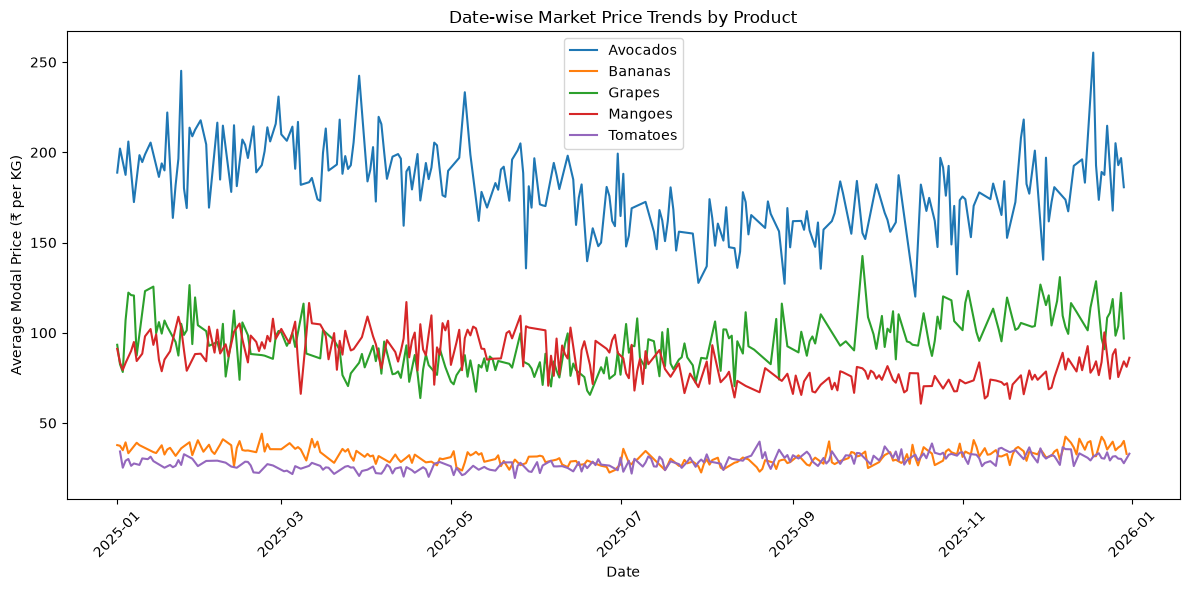

In [6]:
plt.figure(figsize=(12, 6))

for product in date_wise_prices["Product"].unique():
    product_data = date_wise_prices[
        date_wise_prices["Product"] == product
    ]

    plt.plot(
        product_data["Date"],
        product_data["Modal_Price_Per_KG"],
        label=product
    )

plt.title("Date-wise Market Price Trends by Product")
plt.xlabel("Date")
plt.ylabel("Average Modal Price (₹ per KG)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
city_price_comparison = market.groupby(
    ["Product", "City"]
)["Modal_Price_Per_KG"].mean().reset_index()

arbitrage_summary = city_price_comparison.groupby("Product").agg(
    Lowest_City_Price=("Modal_Price_Per_KG", "min"),
    Highest_City_Price=("Modal_Price_Per_KG", "max")
)

arbitrage_summary["Potential_Price_Difference"] = (
    arbitrage_summary["Highest_City_Price"]
    - arbitrage_summary["Lowest_City_Price"]
)

display(arbitrage_summary.round(2))

,Lowest_City_Price,Highest_City_Price,Potential_Price_Difference
Product,,,
Avocados,172.22,193.95,21.72
Bananas,29.93,35.27,5.34
Grapes,86.49,102.79,16.30
Mangoes,79.20,91.06,11.86
Tomatoes,25.41,30.28,4.87


In [8]:
same_day_city_prices = market.pivot_table(
    index=["Date", "Product"],
    columns="City",
    values="Modal_Price_Per_KG",
    aggfunc="mean"
)

# Keep only dates where at least 2 cities have prices
valid_comparisons = same_day_city_prices.dropna(thresh=2)

lowest_price = valid_comparisons.min(axis=1)
highest_price = valid_comparisons.max(axis=1)

same_day_arbitrage = pd.DataFrame({
    "Lowest_Price_City": valid_comparisons.idxmin(axis=1),
    "Lowest_Price": lowest_price,
    "Highest_Price_City": valid_comparisons.idxmax(axis=1),
    "Highest_Price": highest_price,
    "Potential_Price_Gap": highest_price - lowest_price
})

display(same_day_arbitrage.head(20).round(2))

Lowest_Price_City  Lowest_Price Highest_Price_City  \
Date       Product                                                       
2025-01-01 Grapes           Bengaluru         84.39           Tirupati   
           Mangoes             Mumbai         87.90               Pune   
2025-01-02 Avocados             Delhi        180.77            Kolkata   
           Bananas            Kolkata         32.85            Chennai   
           Grapes           Hyderabad         81.59           Tirupati   
2025-01-03 Bananas               Pune         30.26              Kochi   
           Tomatoes              Pune         24.00         Vijayawada   
2025-01-04 Avocados           Chennai        177.72              Kochi   
           Tomatoes             Kochi         27.77             Nagpur   
2025-01-05 Bananas             Mumbai         32.54          Ahmedabad   
           Tomatoes         Hyderabad         24.43             Mumbai   
2025-01-06 Mangoes               Pune         75.69            Kolkata   
           Tomatoes            Nagpur         23.48            Chennai   
2025-01-07 Avocados        Vijayawada        170.05              Delhi   
           Bananas          Hyderabad         35.17          Ahmedabad   
2025-01-08 Bananas              Delhi         38.96          Bengaluru   
           Grapes                Pune         84.48            Chennai   
2025-01-09 Bananas              Delhi         34.54              Kochi   
           Tomatoes         Hyderabad         21.98             Nagpur   
2025-01-10 Avocados             Delhi        190.33         Vijayawada   

                     Highest_Price  Potential_Price_Gap  
Date       Product                                       
2025-01-01 Grapes           102.32                17.93  
           Mangoes           94.26                 6.36  
2025-01-02 Avocados         219.97                39.20  
           Bananas           41.88                 9.03  
           Grapes            83.53                 1.94  
2025-01-03 Bananas           39.63                 9.37  
           Tomatoes          26.48                 2.48  
2025-01-04 Avocados         197.32                19.60  
           Tomatoes          30.44                 2.67  
2025-01-05 Bananas           33.97                 1.43  
           Tomatoes          33.52                 9.09  
2025-01-06 Mangoes          104.21                28.52  
           Tomatoes          31.05                 7.57  
2025-01-07 Avocados         177.22                 7.17  
           Bananas           40.97                 5.80  
2025-01-08 Bananas           39.15                 0.19  
           Grapes            90.40                 5.92  
2025-01-09 Bananas           40.92                 6.38  
           Tomatoes          31.58                 9.60  
2025-01-10 Avocados         198.87                 8.54

In [9]:
top_opportunities = same_day_arbitrage.reset_index()

top_opportunities = top_opportunities.sort_values(
    by="Potential_Price_Gap",
    ascending=False
)

display(top_opportunities.head(10).round(2))

C:\Users\sanga\AppData\Local\Temp\ipykernel_22312\1996321621.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(top_opportunities.head(10).round(2))


,Date,Product,Lowest_Price_City,Lowest_Price,Highest_Price_City,Highest_Price,Potential_Price_Gap
129,2025-03-23,Avocados,Vijayawada,151.13,Kolkata,234.72,83.59
198,2025-05-12,Avocados,Mumbai,137.39,Kochi,218.79,81.40
91,2025-02-24,Avocados,Tirupati,179.73,Nagpur,249.84,70.11
140,2025-03-27,Avocados,Pune,175.89,Ahmedabad,243.79,67.90
513,2025-12-27,Avocados,Hyderabad,162.69,Chennai,223.09,60.40
41,2025-01-24,Avocados,Kolkata,216.27,Nagpur,274.11,57.84
21,2025-01-11,Avocados,Chennai,170.48,Kolkata,227.21,56.73
203,2025-05-14,Avocados,Bengaluru,141.08,Vijayawada,197.69,56.61
225,2025-05-30,Avocados,Vijayawada,136.40,Nagpur,188.08,51.68
508,2025-12-25,Avocados,Vijayawada,150.71,Mumbai,201.72,51.01


In [10]:
top_10 = top_opportunities.head(10).copy()

numeric_columns = top_10.select_dtypes(
    include="number"
).columns

top_10[numeric_columns] = top_10[numeric_columns].round(2)

display(top_10)

,Date,Product,Lowest_Price_City,Lowest_Price,Highest_Price_City,Highest_Price,Potential_Price_Gap
129,2025-03-23,Avocados,Vijayawada,151.13,Kolkata,234.72,83.59
198,2025-05-12,Avocados,Mumbai,137.39,Kochi,218.79,81.40
91,2025-02-24,Avocados,Tirupati,179.73,Nagpur,249.84,70.11
140,2025-03-27,Avocados,Pune,175.89,Ahmedabad,243.79,67.90
513,2025-12-27,Avocados,Hyderabad,162.69,Chennai,223.09,60.40
41,2025-01-24,Avocados,Kolkata,216.27,Nagpur,274.11,57.84
21,2025-01-11,Avocados,Chennai,170.48,Kolkata,227.21,56.73
203,2025-05-14,Avocados,Bengaluru,141.08,Vijayawada,197.69,56.61
225,2025-05-30,Avocados,Vijayawada,136.40,Nagpur,188.08,51.68
508,2025-12-25,Avocados,Vijayawada,150.71,Mumbai,201.72,51.01


In [11]:
product_price_summary.to_csv(
    "../outputs/product_price_summary.csv"
)

city_product_prices.to_csv(
    "../outputs/city_product_prices.csv"
)

price_variation.to_csv(
    "../outputs/product_price_variation.csv"
)

date_wise_prices.to_csv(
    "../outputs/date_wise_price_trends.csv",
    index=False
)

same_day_arbitrage.to_csv(
    "../outputs/same_day_price_comparison.csv"
)

top_opportunities.to_csv(
    "../outputs/top_10_price_opportunities.csv",
    index=False
)

print("All market analysis files saved successfully!")

All market analysis files saved successfully!
